# Judy's scratch: EDA for choosing filter rules

Graphs on the **raw** data (`RAW_interactions.csv`, `RAW_recipes.csv`) to help decide our own filter rules.

`rating = 0` means a review left without stars, so it's shown in the rating distribution but **left out of every average rating**. Review counts include all interactions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../dataset/"
plt.rcParams.update({"figure.figsize": (6, 3.5), "axes.grid": True, "grid.alpha": 0.3})

inter = pd.read_csv(DATA_PATH + "RAW_interactions.csv")
recipes = pd.read_csv(DATA_PATH + "RAW_recipes.csv").set_index("id")
rated = inter[inter.rating > 0]   # star ratings only (1-5)

# per-user / per-recipe stats
uc = inter.groupby("user_id").size()               # reviews per user
um = rated.groupby("user_id").rating.mean()        # avg star rating per user
un = rated.groupby("user_id").size()               # star ratings per user
ic = inter.groupby("recipe_id").size()             # reviews per recipe
im = rated.groupby("recipe_id").rating.mean()      # avg star rating per recipe
inn = rated.groupby("recipe_id").size()            # star ratings per recipe

print(f"interactions {len(inter):,} | users {len(uc):,} | recipes {len(recipes):,} | rating 0: {(inter.rating == 0).mean():.1%}")

interactions 1,132,367 | users 226,570 | recipes 231,637 | rating 0: 5.4%


In [2]:
# helpers
def row(n):
    """One row of n panels, each the same size (14 x 3.6 for a row of 3)."""
    return plt.subplots(1, n, figsize=(14 / 3 * n, 3.6))

def log_bins(x, n=40):
    return np.unique(np.logspace(0, np.log10(x.max() + 1), n).astype(int))

def binned_mean_ci(x, y, bins, min_n=30):
    """Mean of y (with 95% CI) within each x bin that has >= min_n points."""
    idx = np.digitize(x, bins) - 1
    n = np.bincount(idx, minlength=len(bins))
    s = np.bincount(idx, weights=y, minlength=len(bins))
    s2 = np.bincount(idx, weights=y ** 2, minlength=len(bins))
    keep = n >= min_n
    mean = s[keep] / n[keep]
    sd = np.sqrt(s2[keep] / n[keep] - mean ** 2)
    return bins[keep], mean, 1.96 * sd / np.sqrt(n[keep])

def mean_ci_by(x, y, min_n=100):
    """Mean of y (with 95% CI) for each distinct x value with >= min_n points."""
    xs, ms, cis = [], [], []
    for v in np.unique(x):
        yy = y[x == v]
        if len(yy) >= min_n:
            xs.append(v); ms.append(yy.mean()); cis.append(1.96 * yy.std() / np.sqrt(len(yy)))
    return np.array(xs), np.array(ms), np.array(cis)

def threshold_table(counts, who, ks=(1, 2, 3, 5, 10, 20, 50)):
    c = counts.to_numpy()
    return pd.DataFrame({f"{who}s kept": [(c >= k).sum() for k in ks],
                         f"% of {who}s": [(c >= k).mean() * 100 for k in ks],
                         "% of interactions kept": [c[c >= k].sum() / c.sum() * 100 for k in ks]},
                        index=pd.Index(ks, name=f"min reviews per {who}")).round(1)

## Section 1: Understanding the rating data
Individual ratings, average rating per user and average rating per recipe. The printed stats compare everyone with only those who have at least 5 star ratings, since 1-2 ratings give whole-number averages (the spikes).

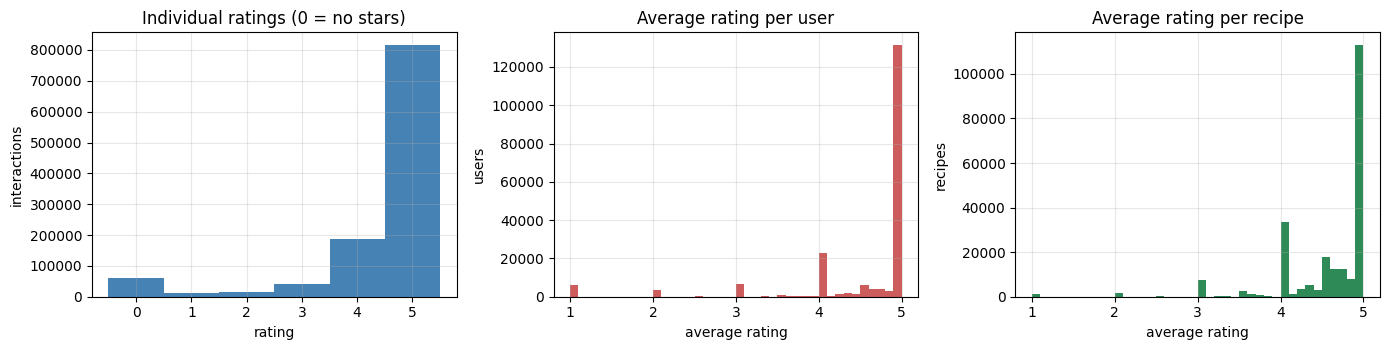

rating shares: 0: 5.4% | 1: 1.1% | 2: 1.2% | 3: 3.6% | 4: 16.5% | 5: 72.1%
users: mean avg 4.56 | exactly 5.0: 66.2% (all) vs 21.8% (>= 5 ratings) | median avg (>= 5 ratings) 4.75
recipes: mean avg 4.58 | exactly 5.0: 48.6% (all) vs 20.8% (>= 5 ratings) | median avg (>= 5 ratings) 4.78


In [3]:
fig, ax = row(3)

vals, cnts = np.unique(inter.rating, return_counts=True)
ax[0].bar(vals, cnts, width=1, color="steelblue")
ax[0].set_title("Individual ratings (0 = no stars)"); ax[0].set_xlabel("rating"); ax[0].set_ylabel("interactions")

bins = np.linspace(1, 5, 41)
ax[1].hist(um, bins=bins, color="indianred")
ax[1].set_title("Average rating per user"); ax[1].set_xlabel("average rating"); ax[1].set_ylabel("users")

ax[2].hist(im, bins=bins, color="seagreen")
ax[2].set_title("Average rating per recipe"); ax[2].set_xlabel("average rating"); ax[2].set_ylabel("recipes")
plt.tight_layout(); plt.show()

print("rating shares: " + " | ".join(f"{v}: {c / cnts.sum():.1%}" for v, c in zip(vals, cnts)))
for who, m, n in [("users", um, un), ("recipes", im, inn)]:
    print(f"{who}: mean avg {m.mean():.2f} | exactly 5.0: {(m == 5).mean():.1%} (all) vs "
          f"{(m[n >= 5] == 5).mean():.1%} (>= 5 ratings) | median avg (>= 5 ratings) {m[n >= 5].median():.2f}")

## Section 2: Understanding user behavior
Reviews per user and star ratings per user (both log-log), and mean average rating (95% interval) for users grouped by how many reviews they have. Every interaction is a written review; the star rating is optional (rating 0 = no stars), so a user can have fewer ratings than reviews but never more. Users with 0 star ratings can't appear on a log axis, so their count is printed instead. The tables show what a "keep users with at least k reviews / ratings" rule would leave.

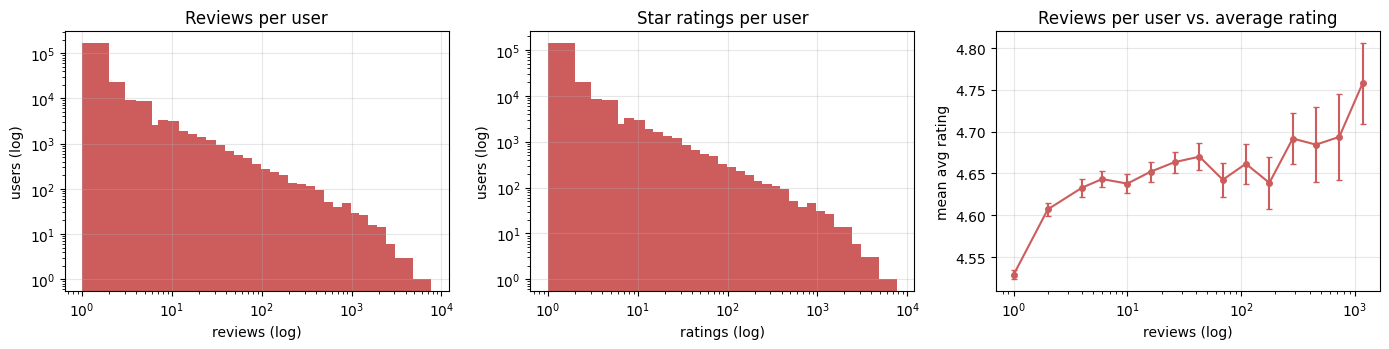

reviews per user: 1 review 73.4% | median 1 | max 7,671
ratings per user: 0 ratings 30,472 users | 1 rating 61.9% | median 1 | max 7,665
users with fewer ratings than reviews: 44,576 (19.7%)


,users kept,% of users,% of interactions kept
min reviews per user,,,
1,226570,100.0,100.0
2,60314,26.6,85.3
3,37576,16.6,81.3
5,23086,10.2,77.0
10,12486,5.5,70.9
20,6687,3.0,64.1
50,2755,1.2,53.6


,users kept,% of users,% of ratings kept
min star ratings per user,,,
1,196098,86.6,100.0
2,55780,24.6,86.9
3,35464,15.7,83.1
5,22018,9.7,78.9
10,12035,5.3,72.9
20,6450,2.8,65.8
50,2669,1.2,55.2


In [4]:
fig, ax = row(3)

ax[0].hist(uc, bins=log_bins(uc), color="indianred")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_title("Reviews per user"); ax[0].set_xlabel("reviews (log)"); ax[0].set_ylabel("users (log)")

ax[1].hist(un, bins=log_bins(un), color="indianred")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Star ratings per user"); ax[1].set_xlabel("ratings (log)"); ax[1].set_ylabel("users (log)")

bx, by, bci = binned_mean_ci(uc[um.index].to_numpy(), um.to_numpy(), log_bins(uc, 20))
ax[2].errorbar(bx, by, yerr=bci, marker="o", ms=4, capsize=2, color="indianred")
ax[2].set_xscale("log")
ax[2].set_title("Reviews per user vs. average rating"); ax[2].set_xlabel("reviews (log)"); ax[2].set_ylabel("mean avg rating")
plt.tight_layout(); plt.show()

un_all = un.reindex(uc.index, fill_value=0)   # star ratings per user, 0 for users who never gave stars
print(f"reviews per user: 1 review {(uc == 1).mean():.1%} | median {uc.median():.0f} | max {uc.max():,}")
print(f"ratings per user: 0 ratings {(un_all == 0).sum():,} users | 1 rating {(un_all == 1).mean():.1%} | median {un_all.median():.0f} | max {un_all.max():,}")
print(f"users with fewer ratings than reviews: {(un_all < uc).sum():,} ({(un_all < uc).mean():.1%})")
display(threshold_table(uc, "user"))
threshold_table(un_all, "user").rename_axis("min star ratings per user").rename(columns={"% of interactions kept": "% of ratings kept"})

## Section 3: Understanding recipe characteristics
Number of ingredients, number of steps (40+ grouped into the last bar), and reviews per recipe (log-log).

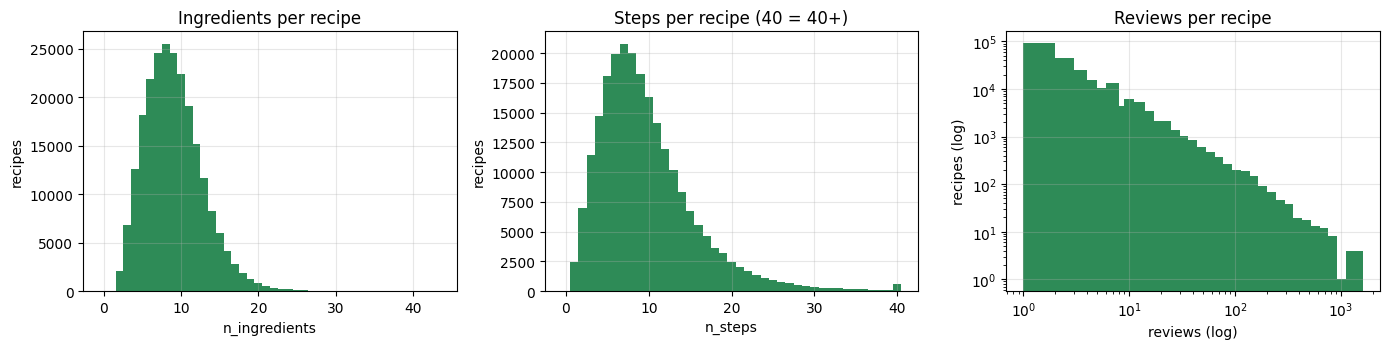

n_ingredients: min 1 | 1% 3 | median 9 | 99% 20 | max 43
n_steps: min 0 | 1% 1 | median 9 | 99% 30 | max 145
recipes with 0 steps: 1 | 40+ steps: 628
recipes with 1 review: 39.7% | median 2 | max 1,613


,recipes kept,% of recipes,% of interactions kept
min reviews per recipe,,,
1,231637,100.0,100.0
2,139684,60.3,91.9
3,94564,40.8,83.9
5,53593,23.1,71.7
10,21399,9.2,53.4
20,7982,3.4,37.7
50,2164,0.9,22.7


In [5]:
fig, ax = row(3)

ni = recipes.n_ingredients.to_numpy()
ax[0].bar(np.arange(ni.max() + 1), np.bincount(ni), width=1, color="seagreen")
ax[0].set_title("Ingredients per recipe"); ax[0].set_xlabel("n_ingredients"); ax[0].set_ylabel("recipes")

ns = recipes.n_steps.to_numpy()
ax[1].bar(np.arange(41), np.bincount(np.clip(ns, 0, 40)), width=1, color="seagreen")
ax[1].set_title("Steps per recipe (40 = 40+)"); ax[1].set_xlabel("n_steps"); ax[1].set_ylabel("recipes")

ax[2].hist(ic, bins=log_bins(ic), color="seagreen")
ax[2].set_xscale("log"); ax[2].set_yscale("log")
ax[2].set_title("Reviews per recipe"); ax[2].set_xlabel("reviews (log)"); ax[2].set_ylabel("recipes (log)")
plt.tight_layout(); plt.show()

for name, v in [("n_ingredients", ni), ("n_steps", ns)]:
    p1, p50, p99 = np.percentile(v, [1, 50, 99])
    print(f"{name}: min {v.min()} | 1% {p1:.0f} | median {p50:.0f} | 99% {p99:.0f} | max {v.max()}")
print(f"recipes with 0 steps: {(ns == 0).sum()} | 40+ steps: {(ns >= 40).sum()}")
print(f"recipes with 1 review: {(ic == 1).mean():.1%} | median {ic.median():.0f} | max {ic.max():,}")
threshold_table(ic, "recipe")

## Section 4: Exploring relationships
Mean recipe rating (95% interval) by number of reviews, ingredients and steps. Ingredients and steps only show values with at least 100 rated recipes; note the narrow y-axes. Then the rating mix for recipes grouped by how many reviews they have.

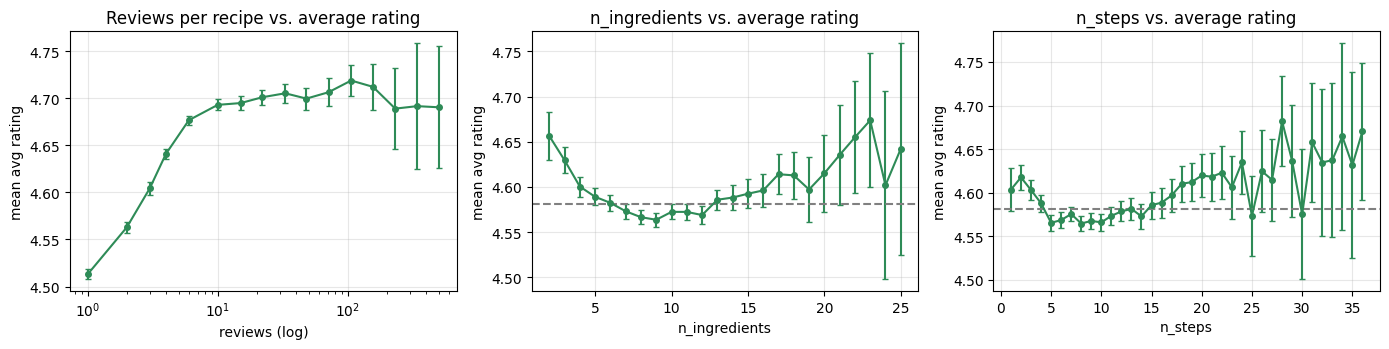

overall mean recipe avg rating (dashed line): 4.58


In [6]:
fig, ax = row(3)
feat = recipes.loc[im.index]          # recipe features, aligned with im
y = im.to_numpy()

bx, by, bci = binned_mean_ci(ic[im.index].to_numpy(), y, log_bins(ic, 20))
ax[0].errorbar(bx, by, yerr=bci, marker="o", ms=4, capsize=2, color="seagreen")
ax[0].set_xscale("log")
ax[0].set_title("Reviews per recipe vs. average rating"); ax[0].set_xlabel("reviews (log)"); ax[0].set_ylabel("mean avg rating")

for a, col, cap in [(ax[1], "n_ingredients", None), (ax[2], "n_steps", 40)]:
    xs, ms, cis = mean_ci_by(feat[col].to_numpy(), y)
    if cap: keep = xs <= cap; xs, ms, cis = xs[keep], ms[keep], cis[keep]
    a.errorbar(xs, ms, yerr=cis, marker="o", ms=4, capsize=2, color="seagreen")
    a.axhline(y.mean(), c="gray", ls="--")
    a.set_title(f"{col} vs. average rating"); a.set_xlabel(col); a.set_ylabel("mean avg rating")
plt.tight_layout(); plt.show()
print(f"overall mean recipe avg rating (dashed line): {y.mean():.2f}")

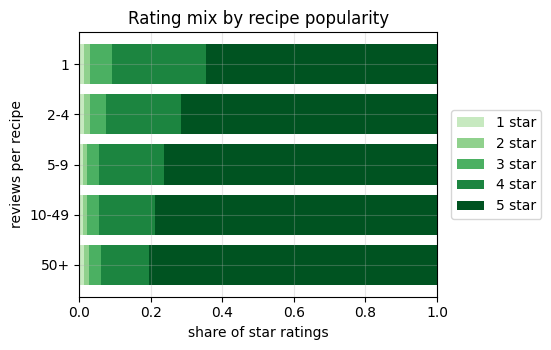

,1 star %,2 star %,3 star %,4 star %,5 star %,ratings
reviews per recipe,,,,,,
1,1.3,1.7,6.1,26.2,64.7,87216
2-4,1.4,1.4,4.6,21.0,71.6,216978
5-9,1.0,1.1,3.5,18.0,76.4,197389
10-49,1.1,1.2,3.2,15.6,78.9,327907
50+,1.3,1.4,3.4,13.3,80.6,242030


In [7]:
# rating mix by recipe popularity
edges = np.array([1, 2, 5, 10, 50])
labels = ["1", "2-4", "5-9", "10-49", "50+"]
grp = np.digitize(ic[rated.recipe_id].to_numpy(), edges) - 1    # popularity group of each rating
mix = np.array([np.bincount(rated.rating.to_numpy()[grp == g], minlength=6)[1:] for g in range(5)])
share = mix / mix.sum(1, keepdims=True)

fig, ax = row(2)
ax = ax[0]; fig.delaxes(fig.axes[1])   # one panel, same size as the others; legend uses the space on the right
left = np.zeros(5)
for s, color in zip(range(5), plt.cm.Greens(np.linspace(0.25, 0.95, 5))):
    ax.barh(labels, share[:, s], left=left, color=color, label=f"{s + 1} star")
    left += share[:, s]
ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_title("Rating mix by recipe popularity"); ax.set_xlabel("share of star ratings"); ax.set_ylabel("reviews per recipe")
plt.tight_layout(); plt.show()

pd.DataFrame(share * 100, index=pd.Index(labels, name="reviews per recipe"),
             columns=[f"{s} star %" for s in range(1, 6)]).assign(ratings=mix.sum(1)).round(1)